# Distil traces and protect existing skills

    You maintain an accounts-payable parser. Invoice **SF-157375** has three lines and a printed
    amount due of **USD 1,158.82**. Its line quantities and prices yield a net of **USD 1,082.07**.
    Adding the printed tax of **USD 75.74** gives **USD 1,157.81**. Which total should the assistant
    put into the training record? Open the first example cell to check the source and grade the
    candidate answers.

    Your next adapter needs to handle invoices with several rows while preserving extraction on
    familiar one-line invoices. The training batch has a fixed number of places. Decide whether to
    reserve some for familiar examples, and whether to teach the calculation alongside the record.

    Select a **Tesla T4** in Colab and run all cells in order. Allow **35–55 minutes** for the main
    comparisons including setup. The optional diagnostic may need another **10–20 minutes**.
    The inputs are synthetic invoices and the teacher runs locally. [Read the lesson](https://docs.recohut.com/courses/advanced-llm-fine-tuning/2-compare-training-stages/05-distil-verified-traces).

## 0. Prepare the runtime

    The public Qwen checkpoint is pinned by revision. The shared T4 runtime can reuse its cached
    weights. Training uses the course's explicit assistant-token batching and loss loop with PEFT
    LoRA. Evaluation generates one answer per invoice with a fixed greedy decoding budget.

In [1]:
import subprocess
import sys

PINS = ('transformers==4.51.3', 'peft==0.15.2', 'accelerate==1.6.0', 'matplotlib==3.10.8', 'pandas==2.3.3', 'numpy==2.2.6')
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PINS], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers==4.51.3', 'peft==0.15.2', 'accelerate==1.6.0', 'matplotlib==3.10.8', 'pandas==2.3.3', 'numpy==2.2.6'], returncode=0)

In [2]:
import torch

if not torch.cuda.is_available() or "T4" not in torch.cuda.get_device_name(0):
    raise RuntimeError("Select a Tesla T4 in Colab before running the fitted comparison.")

## 1. Read the fixture, contract and shared helpers

    The independent parser checks JSON keys, types and every captured value. The catalogue supplies
    visible text and reference records. Both the teacher and the scorer work on local data. The
    teacher's calculation line is checked separately from the source fields in its final record.

In [3]:
"""Versioned synthetic invoices and independent record scoring for the course."""

from __future__ import annotations

import json
import random
import re
from collections import Counter
from dataclasses import dataclass
from datetime import date, timedelta
from typing import Any

CATALOG_VERSION = "course-invoice-v1"
SPLIT_SIZES = {"train": 576, "dev": 72, "familiar": 96, "novel": 96, "independent": 48, "release": 120}
VISIBLE_CONTRACT = (
    "Extract exactly one JSON object with invoice_id, issued_on (YYYY-MM-DD), supplier, "
    "currency (ISO code), line_items (description, quantity, unit_minor), subtotal_minor, "
    "tax_minor, and total_minor. Preserve line order and convert currency amounts to integer cents. "
    "Use null only for a missing or ambiguous field. Do not rewrite printed amounts, invent fields, or add explanations."
)

@dataclass(frozen=True)
class Line:
    description: str
    quantity: int
    unit_minor: int


@dataclass(frozen=True)
class Invoice:
    key: str
    family: str
    supplier: str
    issued_on: str
    currency: str
    items: tuple[Line, ...]
    tax_minor: int | None
    locale: str
    split: str
    layout: str = "register"
    printed_total_minor: int | None = None


def invoice_record(invoice: Invoice) -> dict[str, Any]:
    subtotal = sum(line.quantity * line.unit_minor for line in invoice.items)
    total = subtotal + invoice.tax_minor if invoice.tax_minor is not None else None
    if invoice.printed_total_minor is not None:
        total = invoice.printed_total_minor
    return {
        "invoice_id": invoice.key,
        "issued_on": invoice.issued_on,
        "supplier": invoice.supplier,
        "currency": invoice.currency,
        "line_items": [
            {"description": item.description, "quantity": item.quantity, "unit_minor": item.unit_minor}
            for item in invoice.items
        ],
        "subtotal_minor": subtotal,
        "tax_minor": invoice.tax_minor,
        "total_minor": total,
    }


def make_catalog() -> list[Invoice]:
    rng = random.Random(20261126)
    sources = {
        "train": (24, ("register", "memo", "checkout", "ledger")),
        "dev": (6, ("register", "memo", "checkout", "ledger")),
        "familiar": (8, ("register", "memo", "checkout", "ledger")),
        "novel": (8, ("packing", "remittance", "service", "notice")),
        "independent": (4, ("separate",)),
        "release": (10, ("packing", "remittance", "service", "notice", "separate")),
    }
    locales = (("en-US", "USD"), ("en-GB", "GBP"), ("de-DE", "EUR"), ("fr-FR", "EUR"), ("en-US", "CAD"))
    services = ("Cooling filter", "Cable sleeve", "Bench calibration", "Door seal", "Grounding clip",
                "Rack inspection", "Meter label", "Packing insert", "Carrier adjustment", "Mounting plate")
    catalog = []
    seen_keys = set()
    supplier_codes = rng.sample(range(1000, 9999), sum(n for n, _ in sources.values()))
    supplier_index = 0
    for split, (family_count, layouts) in sources.items():
        for family_number in range(family_count):
            supplier_code = supplier_codes[supplier_index]
            supplier_index += 1
            layout = layouts[family_number % len(layouts)]
            family = f"{split}-{family_number:02d}"
            locale, currency = locales[family_number % len(locales)]
            for row in range(SPLIT_SIZES[split] // family_count):
                code = f"SF-{rng.randrange(100000, 1000000)}"
                while code in seen_keys:
                    code = f"SF-{rng.randrange(100000, 1000000)}"
                seen_keys.add(code)
                items = tuple(
                    Line(kind, rng.randint(1, 9), rng.randrange(200, 24800))
                    for kind in rng.sample(services, rng.randrange(1, 4))
                )
                subtotal = sum(x.quantity * x.unit_minor for x in items)
                tax = (subtotal * (7 if currency == "USD" else 13) + 50) // 100
                if split in {"novel", "independent", "release"} and row % 12 == 4:
                    tax = None
                displayed = subtotal + tax + 101 if tax is not None and row % 12 == 7 else None
                issued_on = (date(2025, 1, 1) + timedelta(days=rng.randint(0, 590))).isoformat()
                catalog.append(Invoice(code, family, f"Sample Supplier {supplier_code}", issued_on,
                                       currency, items, tax, locale, split, layout, displayed))
    return catalog


def formatted_money(minor: int | None, locale: str) -> str:
    if minor is None:
        return "-"
    dollars, cents = divmod(minor, 100)
    number = f"{dollars:,}.{cents:02d}"
    if locale == "de-DE":
        return number.replace(",", "_").replace(".", ",").replace("_", ".")
    if locale == "fr-FR":
        return number.replace(",", " ").replace(".", ",")
    return number


def invoice_text(invoice: Invoice) -> str:
    gold = invoice_record(invoice)
    money = lambda value: formatted_money(value, invoice.locale)
    identifier = f"{invoice.key}"
    supplier = invoice.supplier
    issued = invoice.issued_on
    currency = invoice.currency
    subtotal = money(gold["subtotal_minor"])
    tax = money(gold["tax_minor"])
    total = money(gold["total_minor"])
    register = [f"{row.description} | {row.quantity} | {money(row.unit_minor)}" for row in invoice.items]
    inline = [f"{row.quantity} x {row.description} @ {money(row.unit_minor)} per unit" for row in invoice.items]
    service = [f"{row.description}: {money(row.unit_minor)} each for {row.quantity} units" for row in invoice.items]
    if invoice.layout == "register":
        return "\n".join([f"Supplier: {supplier}", f"Invoice: {identifier}", f"Issued: {issued}", f"Currency: {currency}",
                          "Description | Quantity | Unit price", *register,
                          f"Subtotal: {subtotal}", f"Tax: {tax}", f"Amount due: {total}"])
    if invoice.layout == "memo":
        return "\n".join([f"{supplier} billing memo / {issued}", f"Account invoice {identifier} [{currency}]",
                          *inline, f"Total due {total} including tax {tax}; net amount {subtotal}."])
    if invoice.layout == "checkout":
        return "\n".join([f"{identifier} / supplier {supplier}", f"Date of issue {issued} / All amounts {currency}",
                          *service, f"Net {subtotal}", f"Sales tax {tax}", f"Payable {total}"])
    if invoice.layout == "ledger":
        return "\n".join([f"{supplier} | issued {issued} | invoice {identifier}", f"Ledger in {currency}",
                          "Service | Count | Per unit", *register, f"Before tax {subtotal}",
                          f"Tax charged {tax}", f"Balance {total}"])
    if invoice.layout == "packing":
        return "\n".join([f"Billing details / {identifier}", f"Sold by {supplier}", f"Document date {issued}",
                          f"Invoice currency {currency}", f"Balance payable {total}", *service,
                          f"Merchandise {subtotal}", f"Tax {tax}"])
    if invoice.layout == "remittance":
        return "\n".join([f"Remittance advice for {identifier} ({currency})", f"{supplier} / Document issued {issued}",
                          f"Pay this amount {total}", *inline, f"Net charges {subtotal} / Tax {tax}"])
    if invoice.layout == "service":
        return "\n".join([f"Ref {identifier} / {currency}", f"Service fee notice, {issued}", supplier,
                          *[f"Unit {money(row.unit_minor)} / {row.quantity} times / {row.description}" for row in invoice.items],
                          f"Fee subtotal {subtotal}", f"Plus tax {tax}", f"Amount requested {total}"])
    if invoice.layout == "notice":
        return "\n".join([f"{supplier} / statement {identifier}", f"Issued on {issued}",
                          f"Invoice denomination {currency}", "One-off charges", *service,
                          f"Pre-tax {subtotal} / Tax assessment {tax} / Final bill {total}"])
    return "\n".join([f"Document {identifier}", f"Biller {supplier} / As of {issued} / {currency}", *inline,
                      f"Gross {total}", f"Breakdown: net {subtotal} and taxes {tax}."])


def _strict_dict(pairs: list[tuple[str, Any]]) -> dict[str, Any]:
    result: dict[str, Any] = {}
    for key, value in pairs:
        if key in result:
            raise ValueError(f"Duplicate JSON key {key!r}")
        result[key] = value
    return result


def parse_record(completion: str | dict[str, Any]) -> dict[str, Any] | None:
    if isinstance(completion, str):
        try:
            data = json.loads(completion, object_pairs_hook=_strict_dict)
        except (ValueError, TypeError, RecursionError):
            return None
    else:
        data = completion
    keys = {"invoice_id", "issued_on", "supplier", "currency", "line_items", "subtotal_minor", "tax_minor", "total_minor"}
    if not isinstance(data, dict) or set(data) != keys:
        return None
    for name in ("invoice_id", "supplier", "issued_on", "currency"):
        value = data[name]
        if value is not None and (not isinstance(value, str) or not value.strip()):
            return None
    try:
        if data["issued_on"] is not None and date.fromisoformat(data["issued_on"]).isoformat() != data["issued_on"]:
            return None
    except ValueError:
        return None
    if data["currency"] is not None and re.fullmatch("[A-Z]{3}", data["currency"]) is None:
        return None
    for name in ("subtotal_minor", "tax_minor", "total_minor"):
        if data[name] is not None and type(data[name]) is not int:
            return None
    if not isinstance(data["line_items"], list):
        return None
    for row in data["line_items"]:
        if not isinstance(row, dict) or set(row) != {"description", "quantity", "unit_minor"}:
            return None
        if type(row["description"]) is not str or type(row["quantity"]) is not int or type(row["unit_minor"]) is not int:
            return None
        if not row["description"].strip() or row["quantity"] <= 0:
            return None
    return data


def score_record(completion: str | dict[str, Any], invoice: Invoice) -> dict[str, Any]:
    truth = invoice_record(invoice)
    observed = parse_record(completion)
    field_correct = {key: observed is not None and observed.get(key) == value
                     for key, value in truth.items() if key != "line_items"}
    keys = ("description", "quantity", "unit_minor")
    expected = Counter(tuple(r[k] for k in keys) for r in truth["line_items"])
    predicted = Counter(tuple(r[k] for k in keys) for r in observed["line_items"]) if observed is not None else Counter()
    matches = (expected & predicted).total()
    row_count = expected.total() + predicted.total()
    return {"valid": observed is not None, "exact": observed == truth,
            "fields": sum(field_correct.values()) / len(field_correct), "field_correct": field_correct,
            "row_f1": 2 * matches / row_count if row_count else 1.0}


def rules_extract(text: str) -> dict[str, Any] | None:
    lines = text.splitlines()
    if len(lines) < 9 or lines[4] != "Description | Quantity | Unit price":
        return None
    property_names = ("supplier", "invoice_id", "issued_on", "currency")
    headers = ("Supplier: ", "Invoice: ", "Issued: ", "Currency: ")
    if any(not line.startswith(header) for line, header in zip(lines, headers)):
        return None
    data = {name: line.removeprefix(header) for name, line, header in zip(property_names, lines, headers)}

    def minor(text_amount: str) -> int | None:
        if text_amount == "-":
            return None
        if re.fullmatch(r"(?:\d+|\d{1,3}(?:[., ]\d{3})+)[.,]\d{2}", text_amount) is None:
            raise ValueError("Unsupported amount format")
        units, frac = text_amount[:-3], text_amount[-2:]
        return int(re.sub(r"\D", "", units)) * 100 + int(frac)

    try:
        rows = [line.split(" | ") for line in lines[5:-3]]
        data["line_items"] = [{"description": desc, "quantity": int(qty), "unit_minor": minor(unit)}
                              for desc, qty, unit in rows]
        data["subtotal_minor"] = minor(lines[-3].removeprefix("Subtotal: "))
        data["tax_minor"] = minor(lines[-2].removeprefix("Tax: "))
        data["total_minor"] = minor(lines[-1].removeprefix("Amount due: "))
    except ValueError:
        return None
    return parse_record(data)


def examples_for(split: str, limit: int | None = None) -> list[Invoice]:
    found = [invoice for invoice in make_catalog() if invoice.split == split]
    if not found:
        raise ValueError(f"Unknown invoice split {split!r}")
    if limit is None or limit >= len(found):
        return found
    if limit <= 0:
        raise ValueError("Limit must be positive")
    groups: dict[str, list[Invoice]] = {}
    for invoice in found:
        groups.setdefault(invoice.family, []).append(invoice)
    balanced = [invoice for group_rows in zip(*groups.values(), strict=True) for invoice in group_rows]
    return balanced[:limit]

In [4]:
# SPDX-License-Identifier: Apache-2.0
# Adapted from the Together Post-Training Cookbook revision 226e03ca225d6f13434047cf0f45ab3070a29801.
from collections.abc import Callable, Iterable, Sequence
from dataclasses import field
from typing import NamedTuple, TypeVar

Item = TypeVar("Item")

class Turn(NamedTuple):
    prompt: list[int]
    completion: list[int]

class MaskedSequence(NamedTuple):
    input_ids: list[int]
    completion_mask: list[int]

def split_turns(turns: Iterable[Turn]) -> list[MaskedSequence]:
    """Build prefix-stable sequences with a token-aligned completion mask."""
    sequences: list[MaskedSequence] = []
    emitted: list[int] = []
    mask: list[int] = []
    for prompt, completion in turns:
        if len(prompt) < len(emitted) or prompt[: len(emitted)] != emitted:
            if emitted:
                sequences.append(MaskedSequence(emitted, mask))
            mask = [0] * len(prompt)
        else:
            mask = mask + [0] * (len(prompt) - len(emitted))
        emitted = prompt + completion
        mask = mask + [1] * len(completion)
    if emitted:
        sequences.append(MaskedSequence(emitted, mask))
    return sequences

@dataclass(frozen=True)
class TeacherRequest:
    key: str
    messages: Sequence[dict[str, str]]
    meta: dict[str, object] = field(default_factory=dict)

@dataclass(frozen=True)
class TeacherOutput:
    content: str
    ok: bool = True
    truncated: bool = False

def sft_rows(
    requests: Sequence[TeacherRequest],
    outputs: dict[str, TeacherOutput],
    *,
    reject_reason: Callable[[TeacherRequest, TeacherOutput], str | None] | None = None,
) -> tuple[list[dict[str, object]], Counter[str]]:
    """Convert verified procedural teacher outputs to SFT rows and count exclusions."""
    rows: list[dict[str, object]] = []
    dropped: Counter[str] = Counter()
    for request in requests:
        output = outputs.get(request.key)
        if output is None:
            dropped["missing"] += 1
            continue
        if not output.ok:
            dropped["failed"] += 1
            continue
        if output.truncated:
            dropped["truncated"] += 1
            continue
        content = output.content.strip()
        if not content:
            dropped["empty"] += 1
            continue
        reason = reject_reason(request, output) if reject_reason is not None else None
        if reason is not None:
            dropped[reason] += 1
            continue
        assistant = {"role": "assistant", "content": content}
        rows.append({"id": request.key, "messages": [*request.messages, assistant], "meta": dict(request.meta)})
    return rows, dropped

def mix(*groups: Sequence[Item], seed: int = 0) -> list[Item]:
    """Concatenate row groups and shuffle them deterministically."""
    rows = [row for group in groups for row in group]
    random.Random(seed).shuffle(rows)
    return rows

In [5]:
import gc
import hashlib
import time
from collections import defaultdict
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from peft import LoraConfig, PeftModel, get_peft_model
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
MODEL_REV = "7ae557604adf67be50417f59c2c2f167def9a775"
SEED = 42
DEVICE = "cuda"
DTYPE = torch.float16
PROMPT_LIMIT = 512
ANSWER_LIMIT = 256
OUT = Path("lesson-results")
SYSTEM = VISIBLE_CONTRACT
TRAINER_PINS = dict(pin.split("==") for pin in ('transformers==4.51.3', 'peft==0.15.2', 'accelerate==1.6.0', 'matplotlib==3.10.8', 'pandas==2.3.3', 'numpy==2.2.6'))

In [6]:
def dialogs(invoice, system=SYSTEM):
    return [{"role": "system", "content": system}, {"role": "user", "content": invoice_text(invoice)}]

def packed(record):
    return json.dumps(record, ensure_ascii=False, separators=(",", ":"))

def prepare_kernel():
    pins = globals().get("TRAINER_PINS", {})
    installed = {name: version(name) for name in pins}
    if installed != pins:
        raise RuntimeError(f"Restart the kernel and install the pinned training packages: {installed}")
    if not torch.cuda.is_available():
        raise RuntimeError("Select a T4 GPU in Colab before running all cells.")
    name = torch.cuda.get_device_name(0)
    if "T4" not in name:
        raise RuntimeError(f"Expected a Colab T4 for comparable timings; found {name}.")
    OUT.mkdir(exist_ok=True)
    set_seed(SEED)
    tok = AutoTokenizer.from_pretrained(MODEL_ID, revision=MODEL_REV, trust_remote_code=False)
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    print(name, "|", torch.__version__, "| revision", MODEL_REV[:12])
    print("Trainer packages", installed, "| CUDA", torch.version.cuda)
    return tok

def manifest(invoices):
    rows = sorted(
        (invoice.key, invoice.family, invoice.split, invoice_text(invoice), invoice_record(invoice))
        for invoice in invoices
    )
    return hashlib.sha256(packed(rows).encode()).hexdigest()

def model_at(source=MODEL_ID):
    options = {"revision": MODEL_REV} if source == MODEL_ID else {}
    model = AutoModelForCausalLM.from_pretrained(
        source, **options, torch_dtype=DTYPE, device_map={"": DEVICE},
        trust_remote_code=False, attn_implementation="sdpa", use_safetensors=True,
    )
    if source == MODEL_ID and model.config._commit_hash != MODEL_REV:
        raise RuntimeError("Loaded weights do not match the pinned revision.")
    return model

def clean_memory():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

def lora():
    return LoraConfig(
        r=8, lora_alpha=16, lora_dropout=0.0,
        target_modules=["q_proj", "v_proj", "o_proj"], task_type="CAUSAL_LM",
    )

def eos_ids(model, tok):
    value = model.generation_config.eos_token_id
    ids = value if isinstance(value, list) else [value]
    return {token for token in [tok.eos_token_id, *ids] if token is not None}

@torch.inference_mode()
def evaluate(model, tok, invoices, *, system=SYSTEM, answer_limit=ANSWER_LIMIT, extract=lambda text: text):
    model.eval()
    model.config.use_cache = True
    output = []
    eos = eos_ids(model, tok)
    for i in range(0, len(invoices), 8):
        part = invoices[i:i + 8]
        rendered = [tok.apply_chat_template(dialogs(invoice, system), tokenize=False, add_generation_prompt=True)
                    for invoice in part]
        batch = tok(rendered, add_special_tokens=False, return_tensors="pt", padding=True).to(DEVICE)
        if batch.input_ids.shape[1] > PROMPT_LIMIT:
            raise ValueError("An evaluation prompt exceeded the declared token budget.")
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        started = time.perf_counter()
        tokens = model.generate(**batch, max_new_tokens=answer_limit, do_sample=False,
                                pad_token_id=tok.pad_token_id)[:, batch.input_ids.shape[1]:]
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        latency = (time.perf_counter() - started) * 1000 / len(part)
        texts = tok.batch_decode(tokens, skip_special_tokens=True)
        for invoice, token_row, text in zip(part, tokens.tolist(), texts, strict=True):
            boundary = next((index for index, token in enumerate(token_row) if token in eos), None)
            record = score_record(extract(text), invoice)
            output.append({
                "key": invoice.key, "family": invoice.family, "split": invoice.split,
                "valid": float(record["valid"]), "exact": float(record["exact"]),
                "fields": record["fields"], "row_f1": float(record["row_f1"]),
                "natural_completion": boundary is not None,
                "generated_tokens": len(token_row) if boundary is None else boundary + 1,
                "ms_per_example_in_batch": latency,
                "completion": text,
            })
    return output

def evaluate_at(source, tok, invoices, *, adapter=None, **kwargs):
    base = model_at(source)
    model = PeftModel.from_pretrained(base, adapter) if adapter else base
    scores = evaluate(model, tok, invoices, **kwargs)
    del model, base
    clean_memory()
    return scores

def summary(scores):
    mean = lambda key: sum(row[key] for row in scores) / len(scores)
    return {
        "n": len(scores), "exact": mean("exact"), "valid": mean("valid"),
        "row_f1": mean("row_f1"), "natural_completion": mean("natural_completion"),
        "mean_generated_tokens": mean("generated_tokens"),
        "mean_ms_per_example_in_batch": mean("ms_per_example_in_batch"),
    }

def paired_change(before, after, *, score="exact", seed=SEED):
    left = {row["key"]: row for row in before}
    right = {row["key"]: row for row in after}
    assert set(left) == set(right) and len(left) == len(before) == len(after)
    by_family = defaultdict(list)
    for key, row in sorted(left.items()):
        by_family[row["family"]].append(right[key][score] - row[score])
    changes = [value for values in by_family.values() for value in values]
    groups = list(by_family.values())
    rng = random.Random(seed)
    boot = []
    if len(groups) >= 2:
        for _ in range(2000):
            sampled = [value for group in rng.choices(groups, k=len(groups)) for value in group]
            boot.append(sum(sampled) / len(sampled))
    return {
        "delta": sum(changes) / len(changes), "n": len(changes), "families": len(groups),
        "improved": sum(change > 0 for change in changes),
        "regressed": sum(change < 0 for change in changes),
        "tied": sum(change == 0 for change in changes),
        "paired_family_bootstrap_95": np.quantile(boot, [0.025, 0.975]).tolist() if boot else None,
    }

In [7]:
def make_schedule(examples, batch_size=4):
    if not examples or batch_size <= 0:
        raise ValueError("Expected training examples and a positive batch size.")
    return [examples[start : start + batch_size] for start in range(0, len(examples), batch_size)]

def right_pad(examples, pad_id, device):
    width = max(len(example.input_ids) for example in examples)
    ids, attention, labels = [], [], []
    for example in examples:
        n_pad = width - len(example.input_ids)
        ids.append(example.input_ids + [pad_id] * n_pad)
        attention.append([1] * len(example.input_ids) + [0] * n_pad)
        labels.append([token if mask else -100 for token, mask in zip(
            example.input_ids, example.completion_mask, strict=True,
        )] + [-100] * n_pad)
    return {
        key: torch.tensor(rows, dtype=torch.long, device=device)
        for key, rows in (("input_ids", ids), ("attention_mask", attention), ("labels", labels))
    }

def sft_objective(pad_id, device):
    def loss_for(model, examples):
        batch = right_pad(examples, pad_id, device)
        loss = model(**batch).loss
        supervised = int(batch["labels"][:, 1:].ne(-100).sum().item())
        if not supervised:
            raise ValueError("An update needs at least one response token.")
        unpadded = int(batch["attention_mask"].sum().item())
        return loss, supervised, unpadded
    return loss_for

def adapter_train(model, schedule, objective, *, learning_rate, use_cuda):
    """Both arms share the same schedule, optimiser and gradient policy."""
    params = [param for param in model.parameters() if param.requires_grad]
    if not params or not schedule:
        raise ValueError("Expected trainable parameters and a nonempty update schedule.")
    optimiser = torch.optim.AdamW(params, lr=learning_rate)
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda, init_scale=512, growth_interval=10_000)
    torch.manual_seed(SEED)
    model.train()
    model.config.use_cache = False
    if use_cuda:
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()
    losses, supervised_count, batch_token_count, skipped = [], 0, 0, 0
    for batch in schedule:
        optimiser.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_cuda):
            loss, supervised, batch_tokens = objective(model, batch)
        if not torch.isfinite(loss).item():
            raise FloatingPointError("A non-finite training loss invalidates the comparison.")
        scaler.scale(loss).backward()
        scaler.unscale_(optimiser)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        previous_scale = scaler.get_scale()
        scaler.step(optimiser)
        scaler.update()
        skipped += int(scaler.get_scale() < previous_scale)
        losses.append(float(loss.detach().cpu()))
        supervised_count += supervised
        batch_token_count += batch_tokens
    if use_cuda:
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - started
    return {
        "attempted_updates": len(schedule),
        "updates": len(schedule) - skipped,
        "supervised_response_tokens": supervised_count,
        "unpadded_input_tokens": batch_token_count,
        "seconds": elapsed,
        "supervised_tokens_per_second": supervised_count / max(elapsed, 1e-9),
        "peak_gib": torch.cuda.max_memory_allocated() / 2**30 if use_cuda else None,
        "losses": losses,
        "trainable_parameters": sum(parameter.numel() for parameter in params),
    }

In [8]:
def adapter_digest(model):
    digest = hashlib.sha256()
    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue
        if ".lora_" not in name:
            raise AssertionError(f"Unexpected trainable weight {name}.")
        digest.update(name.encode("utf-8"))
        digest.update(parameter.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()

In [9]:
"""Build and audit procedural teacher labels from training invoices."""

BASE = "Prompted base"
DIRECT = "Direct answers"
TARGET = "Target-only traces"
MIXED = "Mixed traces"
EQUAL = "Equal-target diagnostic"
OPENING_ID = "SF-157375"

TRACE_SYSTEM = (
    VISIBLE_CONTRACT.replace("Extract exactly one JSON object", "Return one final JSON object").removesuffix(
        " Do not rewrite printed amounts, invent fields, or add explanations."
    )
    + " Do not rewrite printed amounts or invent fields. A bare JSON object is allowed. "
      "For a worked answer use CALC quantity * unit_minor + ... = net_minor, a newline, "
      "then RECORD and one space before the JSON."
)
RECORD_MARKER = "\nRECORD "
CALC_LINE = re.compile(r"CALC [0-9]+ \* [0-9]+(?: \+ [0-9]+ \* [0-9]+)* = [0-9]+")


def extract_record(text):
    text = text.strip()
    prefix, marker, record = text.partition(RECORD_MARKER)
    if marker and CALC_LINE.fullmatch(prefix):
        return record.strip()
    return text


def calculation(invoice):
    terms = " + ".join(f"{row.quantity} * {row.unit_minor}" for row in invoice.items)
    net = sum(row.quantity * row.unit_minor for row in invoice.items)
    return f"CALC {terms} = {net}"


def teacher_outputs(invoices):
    """Generate and reconcile an accepted and rejected candidate ledger."""
    requests, outputs = [], {}
    fixture_map = {invoice.key: invoice for invoice in invoices}
    if len(fixture_map) != len(invoices) or any(invoice.split != "train" for invoice in invoices):
        raise ValueError("The teacher requires distinct training invoices.")

    for position, invoice in enumerate(invoices):
        record = invoice_record(invoice)
        trace = calculation(invoice)
        correct = trace + RECORD_MARKER + packed(record)
        origin = {"invoice_key": invoice.key, "group": "target" if len(invoice.items) == 3 else "retention"}
        prompts = dialogs(invoice, TRACE_SYSTEM)
        variants = {"verified": TeacherOutput(correct)}
        if position % 17 == 0:
            variants["truncated"] = TeacherOutput(correct[:-8], truncated=True)
        if position % 19 == 0:
            inferred_total = record["subtotal_minor"] + record["tax_minor"]
            if inferred_total == record["total_minor"]:
                inferred_total += 1
            wrong_record = {**record, "total_minor": inferred_total}
            variants["wrong-record"] = TeacherOutput(trace + RECORD_MARKER + packed(wrong_record))
        if position % 23 == 0:
            before, _, net = trace.rpartition(" = ")
            variants["wrong-trace"] = TeacherOutput(f"{before} = {int(net) + 1}{RECORD_MARKER}{packed(record)}")
        for variant, output in variants.items():
            key = f"{invoice.key}/{variant}"
            requests.append(TeacherRequest(key, prompts, {**origin, "variant": variant}))
            outputs[key] = output

    def reject(request, output):
        invoice = fixture_map[request.meta["invoice_key"]]
        prefix, marker, record = output.content.partition(RECORD_MARKER)
        if prefix != calculation(invoice) or not marker:
            return "arithmetic_trace"
        if not score_record(record, invoice)["exact"]:
            return "record_verifier"
        return None

    verified, rejects = sft_rows(requests, outputs, reject_reason=reject)
    accepted_ids = {row["id"] for row in verified}
    if len(verified) != len(invoices) or accepted_ids != {f"{row.key}/verified" for row in invoices}:
        raise AssertionError("Every train invoice needs exactly one accepted trace.")
    ledger = [
        {
            "candidate_id": request.key,
            **request.meta,
            "decision": "accepted" if request.key in accepted_ids else (
                "truncated" if outputs[request.key].truncated else reject(request, outputs[request.key])
            ),
            "completion": outputs[request.key].content,
        }
        for request in requests
    ]
    if Counter(row["decision"] for row in ledger) != Counter(accepted=len(verified), **rejects):
        raise AssertionError("Teacher ledger does not reconcile with filtering totals.")
    return verified, ledger


def locked_slices(catalog):
    """Check fit, development and teaching groups before generating any labels."""
    all_keys = {invoice.key for invoice in catalog}
    if len(all_keys) != len(catalog):
        raise ValueError("Duplicate invoice keys in the catalogue.")
    eligible = [invoice for invoice in catalog if invoice.split != "release"]
    known = {"train", "dev", "familiar", "novel", "independent"}
    if {row.split for row in eligible} != known:
        raise ValueError("The catalogue must contain exactly the declared lesson splits.")
    for field in (lambda row: row.family, lambda row: row.supplier, invoice_text):
        seen = {}
        for invoice in eligible:
            value = field(invoice)
            previous = seen.setdefault(value, invoice.split)
            if previous != invoice.split:
                raise ValueError(f"Overlap between {previous} and {invoice.split}.")
    train = [row for row in eligible if row.split == "train" and len(row.items) in (1, 3)]
    dev = {
        name: [row for row in eligible if row.split == "dev" and len(row.items) == line_count]
        for name, line_count in (("one line", 1), ("three lines", 3))
    }
    heldout = {
        "Difficult": [row for row in eligible if row.split in ("novel", "independent") and len(row.items) == 3],
        "Familiar": [row for row in eligible if row.split == "familiar" and len(row.items) == 1],
    }
    if not train or not all(dev.values()) or not all(heldout.values()):
        raise ValueError("Every declared group needs examples.")
    train_layouts = {row.layout for row in train}
    if train_layouts.intersection(row.layout for row in heldout["Difficult"]):
        raise ValueError("Difficult test layouts must be held out from training.")
    if any(row.layout not in train_layouts for row in heldout["Familiar"]):
        raise ValueError("Familiar test layouts must occur in training.")
    return train, dev, heldout


def matched_teacher_arms(train, size=128, batch_size=4, seed=SEED):
    """Match total updates in the main arms and expose one optional diagnostic schedule."""
    if size <= 0 or batch_size <= 0 or batch_size % 2 or size % batch_size:
        raise ValueError("The positive train size must divide into full, even batches.")
    order = list(train)
    random.Random(seed).shuffle(order)
    opening = next(row for row in order if row.key == OPENING_ID)
    order.remove(opening)
    order.insert(0, opening)
    verified, ledger = teacher_outputs(order)
    groups = {
        name: [row for row in verified if row["meta"]["group"] == name]
        for name in ("target", "retention")
    }
    target, retention = groups["target"][:size], groups["retention"][:size // 2]
    if len(target) != size or len(retention) != size // 2:
        raise ValueError("The teacher returned too few labels to build matched arms.")
    half = batch_size // 2
    mixed = []
    for start in range(0, size // 2, half):
        mixed.extend(mix(target[start:start + half], retention[start:start + half], seed=seed + start))
    equal = [row for row in mixed if row["meta"]["group"] == "target"]
    selections = {DIRECT: mixed, TARGET: target, MIXED: mixed, EQUAL: equal}
    return selections, ledger


def completion(row, *, with_trace):
    response = row["messages"][-1]["content"]
    return response if with_trace else extract_record(response)

In [10]:
"""Build the masked update schedule and record the paired evidence."""

TRAIN_ROWS = 128
TRAIN_BATCH = 4
LEARNING_RATE = 2e-4
SHORT_CAP = 128
RUN_EQUAL_TARGET_DIAGNOSTIC = False


def encode_schedule(selections, tok):
    if tok.pad_token_id is None or tok.eos_token_id is None:
        raise ValueError("The pinned tokenizer must supply padding and end markers.")
    schedules, exposure, lineage = {}, {}, {}
    for arm, rows in selections.items():
        examples, lineage[arm] = [], []
        batch_size = TRAIN_BATCH // 2 if arm == EQUAL else TRAIN_BATCH
        seen = set()
        for position, row in enumerate(rows):
            key = row["meta"]["invoice_key"]
            if key in seen:
                raise ValueError(f"{arm} repeats training invoice {key}.")
            seen.add(key)
            prompt = tok.apply_chat_template(row["messages"][:-1], tokenize=True, add_generation_prompt=True)
            answer = completion(row, with_trace=arm != DIRECT)
            response = tok.encode(answer, add_special_tokens=False) + [tok.eos_token_id]
            if not prompt or len(response) <= 1 or len(prompt) > PROMPT_LIMIT or len(response) > ANSWER_LIMIT:
                raise ValueError(f"The prompt or supervised label for {key} exceeds the declared token contract.")
            sequence, = split_turns([Turn(prompt, response)])
            if sequence.input_ids != prompt + response or sequence.completion_mask != [0] * len(prompt) + [1] * len(response):
                raise AssertionError(f"{key} lost its exact assistant-only token boundary.")
            examples.append(sequence)
            lineage[arm].append({
                "invoice_key": key, "candidate_id": row["id"], "group": row["meta"]["group"],
                "update": position // batch_size + 1, "prompt_tokens": len(prompt),
                "response_tokens": len(response), "completion": answer,
            })
        schedules[arm] = make_schedule(examples, batch_size=batch_size)
        for batch in schedules[arm]:
            masked = right_pad(batch, tok.pad_token_id, "cpu")["labels"]
            for index, row in enumerate(batch):
                expected = [bool(weight) for weight in row.completion_mask]
                expected += [False] * (masked.shape[1] - len(expected))
                if masked[index].ne(-100).tolist() != expected:
                    raise AssertionError("Prompt and padding tokens must be excluded from the loss.")
        exposure[arm] = {
            "rows": len(rows), "updates": len(schedules[arm]), "batch_size": batch_size,
            "target_rows": sum(row["group"] == "target" for row in lineage[arm]),
            "retention_rows": sum(row["group"] == "retention" for row in lineage[arm]),
            "prompt_tokens": sum(row["prompt_tokens"] for row in lineage[arm]),
            "response_tokens": sum(row["response_tokens"] for row in lineage[arm]),
            "max_prompt_tokens": max(row["prompt_tokens"] for row in lineage[arm]),
            "max_response_tokens": max(row["response_tokens"] for row in lineage[arm]),
        }

    main_budget = ("rows", "updates", "batch_size")
    if any(exposure[arm][name] != exposure[MIXED][name] for arm in (DIRECT, TARGET) for name in main_budget):
        raise AssertionError("The main arms must match document and update counts.")
    if [row["messages"][:-1] for row in selections[DIRECT]] != [row["messages"][:-1] for row in selections[MIXED]]:
        raise AssertionError("Direct and mixed must use the same prompts in the same order.")
    matched_targets = [row for row in lineage[MIXED] if row["group"] == "target"]
    if matched_targets != lineage[EQUAL]:
        raise AssertionError("The diagnostic must see the identical target labels at each update.")
    return schedules, exposure, lineage


def fit_trace_adapter(schedule, tok, name):
    set_seed(SEED)
    model = get_peft_model(model_at(), lora(), revision=MODEL_REV)
    initial = adapter_digest(model)
    stats = adapter_train(
        model, schedule, sft_objective(tok.pad_token_id, DEVICE), learning_rate=LEARNING_RATE, use_cuda=True,
    )
    stats["initial_adapter_sha256"] = initial
    stats["trained_adapter_sha256"] = adapter_digest(model)
    checkpoint = OUT / name
    model.save_pretrained(checkpoint, safe_serialization=True)
    del model
    clean_memory()
    return str(checkpoint), stats


def check_training_receipt(training, exposure):
    if len({row["initial_adapter_sha256"] for row in training.values()}) != 1:
        raise AssertionError("All fitted adapters must use the same initial parameters.")
    for arm, stats in training.items():
        plan = exposure[arm]
        if stats["updates"] != plan["updates"] or stats["attempted_updates"] != plan["updates"]:
            raise AssertionError(f"{arm} skipped an optimiser update.")
        if stats["supervised_response_tokens"] != plan["response_tokens"]:
            raise AssertionError(f"{arm} saw an unexpected number of response tokens.")
        if stats["unpadded_input_tokens"] != plan["prompt_tokens"] + plan["response_tokens"]:
            raise AssertionError(f"{arm} saw an unexpected number of input tokens.")
        if stats["initial_adapter_sha256"] == stats["trained_adapter_sha256"]:
            raise AssertionError(f"{arm} did not change its LoRA weights.")


def prepare_evaluation(scores, invoices):
    roster = [(row.key, row.family, row.split) for row in invoices]
    for arm, rows in scores.items():
        if [(row["key"], row["family"], row["split"]) for row in rows] != roster:
            raise AssertionError(f"{arm} returned different evaluation keys, families or ordering.")
        for row, invoice in zip(rows, invoices, strict=True):
            prefix, marker, _ = row["completion"].strip().partition(RECORD_MARKER)
            score = score_record(extract_record(row["completion"]), invoice)
            row.update({
                "line_count": len(invoice.items),
                "trace_present": bool(marker and CALC_LINE.fullmatch(prefix)),
                "trace_correct": bool(marker and prefix == calculation(invoice)),
                "field_correct": score["field_correct"],
            })


def measured_slices(heldout, predictions):
    scores, paired = {}, {}
    contrasts = {
        "mixed_minus_target": (TARGET, MIXED),
        "mixed_minus_direct": (DIRECT, MIXED),
        "mixed_minus_base": (BASE, MIXED),
    }
    if EQUAL in predictions:
        contrasts["mixed_minus_equal_target"] = (EQUAL, MIXED)
    for name, items in heldout.items():
        keys = {row.key for row in items}
        sliced = {arm: [row for row in values if row["key"] in keys] for arm, values in predictions.items()}
        scores[name] = {arm: {**summary(rows), "families": len({row["family"] for row in rows})}
                        for arm, rows in sliced.items()}
        paired[name] = {}
        for contrast, (before, after) in contrasts.items():
            left, right = sliced[before], sliced[after]
            changed = paired_change(left, right)
            changed["both_exact"] = sum(bool(x["exact"] and y["exact"]) for x, y in zip(left, right, strict=True))
            changed["both_wrong"] = changed["tied"] - changed["both_exact"]
            paired[name][contrast] = changed
    return scores, paired


def write_evidence(report, audit, predictions, sensitivity):
    payloads = {"report": report, "audit": audit, "predictions": predictions, "cap-predictions": sensitivity}
    for suffix, payload in payloads.items():
        path = OUT / f"05-{suffix}.json"
        path.write_text(json.dumps(payload, indent=2, allow_nan=False) + "\n", encoding="utf-8")
        print(path)

In [11]:
"""Controlled probability distillation on held-out invoice line counts."""


def soft_cross_entropy(logits, target):
    return -(target * torch.log_softmax(logits.float(), -1)).sum(-1).mean()


def confidence_ece(probabilities, gold, bins=10):
    confidence, prediction = probabilities.max(dim=-1)
    correct = prediction.eq(gold).float()
    error = torch.zeros(())
    for index in range(bins):
        lower, upper = index / bins, (index + 1) / bins
        selected = (confidence >= lower) & ((confidence < upper) if index + 1 < bins else (confidence <= 1))
        if selected.any():
            error += selected.float().mean() * (correct[selected].mean() - confidence[selected].mean()).abs()
    return float(error)


def grade_classes(predicted, gold):
    return {
        str(label + 1): {
            "n": int((gold == label).sum()),
            "correct": int(((gold == label) & (predicted == gold)).sum()),
        }
        for label in range(3)
    }


def soft_split(items):
    # This diagnostic isolates transfer of label noise, so the feature is a deterministic count
    # of visible line-item rows. An end-to-end extraction score is measured separately.
    labels = torch.tensor([len(invoice_record(item)["line_items"]) - 1 for item in items])
    visible_counts = [sum(bool(re.fullmatch(
        r"(?:[^|]+ \| \d+ \| .+|\d+ x .+ per unit|.+ each for \d+ units|Unit .+ / \d+ times / .+)",
        line,
    )) for line in invoice_text(item).splitlines()) for item in items]
    assert all(1 <= count <= 3 for count in visible_counts)
    features = torch.nn.functional.one_hot(torch.tensor(visible_counts) - 1, num_classes=3).float()
    teacher_classes = labels.clone()
    teacher_classes[labels == 2] = 1
    teacher = torch.full_like(features, 0.035)
    teacher.scatter_(1, teacher_classes[:, None], 0.93)
    return features, labels, teacher


def run_soft_target_diagnostic(catalog, device):
    groups = {
        name: [row for row in catalog if row.split == split]
        for name, split in (("train", "train"), ("gold_validation", "dev"), ("test", "novel"))
    }
    # Keep whole families out of checkpoint selection when assigning calibration rows.
    families = sorted({row.family for row in groups["gold_validation"]})
    calibration_families = set(families[::2])
    groups["calibration"] = [row for row in groups["gold_validation"] if row.family in calibration_families]
    groups["gold_validation"] = [row for row in groups["gold_validation"] if row.family not in calibration_families]
    assert sum(len({row.key for row in group}) for group in groups.values()) == len({
        row.key for group in groups.values() for row in group
    })
    assert sum(len({row.family for row in group}) for group in groups.values()) == len({
        row.family for group in groups.values() for row in group
    })
    splits = {name: soft_split(rows) for name, rows in groups.items()}
    audit = {name: grade_classes(teacher.argmax(-1), gold) for name, (_, gold, teacher) in splits.items()}
    print("Teacher versus gold before fitting:", audit)
    absent = [label for label, row in audit["test"].items() if row["n"] == 0]
    if absent:
        print("Absent held-out classes:", absent)
    blind = [int(label) - 1 for label, row in audit["gold_validation"].items() if row["n"] and not row["correct"]]
    assert blind == [2], "The declared teacher fault must be visible in gold validation."
    train_x, train_y, train_teacher = splits["train"]
    val_x, val_y, val_teacher = splits["gold_validation"]
    dtype = torch.float16 if device == "cuda" else torch.float32
    results = {}
    for mode in ("soft", "hybrid"):
        # A fixed gold warm start represents an incumbent student before distillation.
        weight = torch.nn.Parameter(torch.eye(3, device=device) * 0.5)
        bias = torch.nn.Parameter(torch.zeros(3, device=device))
        optimiser = torch.optim.SGD((weight, bias), lr=1.0)
        targets = train_teacher.clone()
        if mode == "hybrid":
            for label in blind:
                selected = train_y == label
                targets[selected] = torch.nn.functional.one_hot(train_y[selected], num_classes=3).float()
        def logits(features):
            return features.to(device=device, dtype=dtype) @ weight.to(dtype=dtype) + bias.to(dtype=dtype)
        epochs, checkpoints = [], []
        for epoch in range(21):
            if epoch:
                optimiser.zero_grad()
                loss = soft_cross_entropy(logits(train_x), targets.to(device))
                loss.backward()
                optimiser.step()
            with torch.no_grad():
                prediction = logits(val_x).cpu().argmax(-1)
                epochs.append({
                    "epoch": epoch,
                    "gold_accuracy": float(prediction.eq(val_y).float().mean()),
                    "teacher_agreement": float(prediction.eq(val_teacher.argmax(-1)).float().mean()),
                })
                checkpoints.append((weight.detach().clone(), bias.detach().clone()))

        selected = {}
        for criterion in ("teacher_agreement", "gold_accuracy"):
            epoch = max(epochs, key=lambda row: (row[criterion], row["epoch"]))["epoch"]
            with torch.no_grad():
                weight.copy_(checkpoints[epoch][0])
                bias.copy_(checkpoints[epoch][1])
                cal_x, cal_y, _ = splits["calibration"]
                cal_logits = logits(cal_x).float().cpu()
                temperatures = torch.logspace(-1, 1, 81)
                losses = [float(torch.nn.functional.cross_entropy(cal_logits / temp, cal_y)) for temp in temperatures]
                temperature = float(temperatures[losses.index(min(losses))])
                test_x, test_y, _ = splits["test"]
                test_logits = logits(test_x).float().cpu()
                selected[criterion] = {
                    **epochs[epoch],
                    "temperature": temperature,
                    "calibration_examples": len(cal_y),
                    "calibration_nll_before": float(torch.nn.functional.cross_entropy(cal_logits, cal_y)),
                    "calibration_nll_after": min(losses),
                    "test_gold_by_class": grade_classes(test_logits.argmax(-1), test_y),
                    "test_ece_before": confidence_ece(test_logits.softmax(-1), test_y),
                    "test_ece_after": confidence_ece((test_logits / temperature).softmax(-1), test_y),
                }
        results[mode] = {"epochs": epochs, "selected": selected}
    return {"teacher_vs_gold": audit, "test_classes_absent": absent, "hybrid_override_classes": [i+1 for i in blind],
            "fit_dtype": str(dtype), "arms": results,
            "split_keys": {name: [row.key for row in rows] for name, rows in groups.items()}}

## 2. Grade the teacher and freeze the comparison

    Compare the worked trace to the invoice. A calculation that looks right can still accompany a
    wrongly rewritten printed total. A correct record can also accompany bad arithmetic. The ledger
    gives the outcome for each candidate, including a deliberately cut-off answer. Keep the source's
    printed total in the record and let a separate downstream check flag the discrepancy.

    The three-line target evaluation uses novel and independent layouts. The one-line retention
    evaluation uses known layouts with unseen suppliers. The development split compares difficulty
    within known layouts. Invoice keys, suppliers, families and visible inputs stay disjoint by split.
    No release record enters the experiment.

In [12]:
catalog = make_catalog()
train, dev, heldout = locked_slices(catalog)
selections, ledger = matched_teacher_arms(train, TRAIN_ROWS, TRAIN_BATCH)
opening = next(item for item in train if item.key == OPENING_ID)
opening_candidates = [row for row in ledger if row["invoice_key"] == OPENING_ID]
print(invoice_text(opening))
for candidate in opening_candidates:
    print("\n" + candidate["decision"] + "\n" + candidate["completion"])
print("Teacher candidates by decision:", dict(Counter(row["decision"] for row in ledger)))
print("Development roster:", {name: len(rows) for name, rows in dev.items()})
print("Locked evaluation roster:", {name: len(rows) for name, rows in heldout.items()})

Supplier: Sample Supplier 8777
Invoice: SF-157375
Issued: 2026-06-12
Currency: USD
Description | Quantity | Unit price
Cooling filter | 9 | 21.85
Packing insert | 3 | 87.63
Mounting plate | 3 | 207.51
Subtotal: 1,082.07
Tax: 75.74
Amount due: 1,158.82

accepted
CALC 9 * 2185 + 3 * 8763 + 3 * 20751 = 108207
RECORD {"invoice_id":"SF-157375","issued_on":"2026-06-12","supplier":"Sample Supplier 8777","currency":"USD","line_items":[{"description":"Cooling filter","quantity":9,"unit_minor":2185},{"description":"Packing insert","quantity":3,"unit_minor":8763},{"description":"Mounting plate","quantity":3,"unit_minor":20751}],"subtotal_minor":108207,"tax_minor":7574,"total_minor":115882}

truncated
CALC 9 * 2185 + 3 * 8763 + 3 * 20751 = 108207
RECORD {"invoice_id":"SF-157375","issued_on":"2026-06-12","supplier":"Sample Supplier 8777","currency":"USD","line_items":[{"description":"Cooling filter","quantity":9,"unit_minor":2185},{"description":"Packing insert","quantity":3,"unit_minor":8763},{"de

## 3. Test probability targets with a deliberately biased teacher

    This controlled classification diagnostic uses visible line counts as features. Its scripted
    teacher scores every three-line invoice as two lines. The train, checkpoint validation, temperature
    calibration and novel test groups are family-disjoint. Start both students from the same fixed gold
    incumbent, then compare selection by teacher agreement and by gold validation accuracy. Break selection
    ties towards the latest epoch. The hybrid
    fit replaces only the blind class's training targets with gold labels. Fit temperature on its own
    split by minimising gold cross-entropy and measure top-label ECE on the novel test split.
    Temperature cannot repair an incorrect argmax. This diagnostic isolates label transfer. The
    separate trace comparison measures whole-invoice extraction.

In [13]:
soft_result = run_soft_target_diagnostic(catalog, DEVICE)
OUT.mkdir(parents=True, exist_ok=True)
(OUT / "05-soft-targets.json").write_text(json.dumps(soft_result, indent=2) + "\n")
print("Absent novel test classes:", soft_result["test_classes_absent"])
for arm, result in soft_result["arms"].items():
    print(arm, result["selected"])

Teacher versus gold before fitting: {'train': {'1': {'n': 187, 'correct': 187}, '2': {'n': 195, 'correct': 195}, '3': {'n': 194, 'correct': 0}}, 'gold_validation': {'1': {'n': 9, 'correct': 9}, '2': {'n': 9, 'correct': 9}, '3': {'n': 18, 'correct': 0}}, 'test': {'1': {'n': 37, 'correct': 37}, '2': {'n': 27, 'correct': 27}, '3': {'n': 32, 'correct': 0}}, 'calibration': {'1': {'n': 10, 'correct': 10}, '2': {'n': 16, 'correct': 16}, '3': {'n': 10, 'correct': 0}}}


Absent novel test classes: []
soft {'teacher_agreement': {'epoch': 20, 'gold_accuracy': 0.5, 'teacher_agreement': 1.0, 'temperature': 1.8836491107940674, 'calibration_examples': 36, 'calibration_nll_before': 0.9556662440299988, 'calibration_nll_after': 0.8195742964744568, 'test_gold_by_class': {'1': {'n': 37, 'correct': 37}, '2': {'n': 27, 'correct': 27}, '3': {'n': 32, 'correct': 0}}, 'test_ece_before': 0.21369695663452148, 'test_ece_after': 0.1818317025899887}, 'gold_accuracy': {'epoch': 0, 'gold_accuracy': 1.0, 'teacher_agreement': 0.5, 'temperature': 0.10000000149011612, 'calibration_examples': 36, 'calibration_nll_before': 0.7943766713142395, 'calibration_nll_after': 0.01338590495288372, 'test_gold_by_class': {'1': {'n': 37, 'correct': 37}, '2': {'n': 27, 'correct': 27}, '3': {'n': 32, 'correct': 32}}, 'test_ece_before': 0.5481373071670532, 'test_ece_after': 0.013296782970428467}}
hybrid {'teacher_agreement': {'epoch': 20, 'gold_accuracy': 1.0, 'teacher_agreement': 0.5, 'temperatu

## 4. Verify the token budget and screen the difficulty gap

    Direct answers and Mixed traces use the exact same ordered inputs. The other main arm spends
    every position on a three-line invoice. All main runs use the same update count and batch size.
    Direct-answer targets start at the JSON. Trace targets start at CALC. Prompt and padding tokens
    have label `-100`, and the end marker is supervised. The development result is a descriptive
    check of the assumed difficulty gap. It does not change the locked test roster or the training mix.

In [14]:
tok = prepare_kernel()
schedules, exposure, train_lineage = encode_schedule(selections, tok)
display(pd.DataFrame(exposure).T)
dev_roster = [item for rows in dev.values() for item in rows]
dev_run = evaluate_at(MODEL_ID, tok, dev_roster, system=TRACE_SYSTEM, extract=extract_record)
prepare_evaluation({BASE: dev_run}, dev_roster)
dev_scores = {
    name: {**summary([row for row in dev_run if row["line_count"] == count]),
           "families": len({row.family for row in dev[name]})}
    for name, count in (("one line", 1), ("three lines", 3))
}
display(pd.DataFrame(dev_scores).T)

Tesla T4 | 2.14.1+cu130 | revision 7ae557604adf
Trainer packages {'transformers': '4.51.3', 'peft': '0.15.2', 'accelerate': '1.6.0', 'matplotlib': '3.10.8', 'pandas': '2.3.3', 'numpy': '2.2.6'} | CUDA 13.0


,rows,updates,batch_size,target_rows,retention_rows,prompt_tokens,response_tokens,max_prompt_tokens,max_response_tokens
Direct answers,128,32,4,64,64,28403,14102,247,132
Target-only traces,128,32,4,128,0,30478,21739,248,174
Mixed traces,128,32,4,64,64,28403,18029,247,174
Equal-target diagnostic,64,32,2,64,0,15199,10864,247,174


,n,exact,valid,row_f1,natural_completion,mean_generated_tokens,mean_ms_per_example_in_batch,families
one line,19.0,0.0,0.0,0.0,1.00,163.263158,871.645404,6.0
three lines,28.0,0.0,0.0,0.0,0.25,243.142857,1075.562424,6.0


## 5. Spend a fixed number of updates

    Train three rank-8 LoRA adapters from the same pinned base and initial seed. Mixed traces replaces
    half of the difficult labels with retention labels. That comparison measures the full mix policy
    at fixed documents and updates. Direct answers keeps those mixed prompts and drops the trace from
    every answer, which isolates the label-format choice at fixed input exposure.

    For an attribution follow-up, set `RUN_EQUAL_TARGET_DIAGNOSTIC = True` before this cell. The
    extra arm removes familiar examples from each mixed batch. It keeps the exact difficult inputs
    and labels at each update while changing the batch size and supervised-token distribution.

In [15]:
names = [DIRECT, TARGET, MIXED]
if RUN_EQUAL_TARGET_DIAGNOSTIC:
    names.append(EQUAL)
adapters, training = {}, {}
for index, arm in enumerate(names):
    adapters[arm], training[arm] = fit_trace_adapter(schedules[arm], tok, f"05-arm-{index}")
check_training_receipt(training, exposure)
display(pd.DataFrame(training).T.drop(columns=["losses", "initial_adapter_sha256", "trained_adapter_sha256"]))

,attempted_updates,updates,supervised_response_tokens,unpadded_input_tokens,seconds,supervised_tokens_per_second,peak_gib,trainable_parameters
Direct answers,32,32,14102,42505,11.60574,1215.088434,5.22665,884736
Target-only traces,32,32,21739,52217,12.137243,1791.098691,5.71985,884736
Mixed traces,32,32,18029,46432,11.331899,1590.995466,5.703119,884736


## 6. Score the difficult and familiar slices

    Every method sees the same invoice-only evaluation prompt. Strict exact record requires a parsed
    object equal to the reference, including row order and printed amounts. A declared calculation
    line may precede the record. Arithmetic agreement on that line and natural stopping are scored
    separately. Draw paired intervals by resampling supplier families, and report denominators for
    each slice. Assess retention relative to the prompted base as well as to Target-only traces.

In [16]:
evaluation = [item for items in heldout.values() for item in items]
heldout_predictions = {BASE: evaluate_at(MODEL_ID, tok, evaluation, system=TRACE_SYSTEM, extract=extract_record)}
for arm, adapter in adapters.items():
    heldout_predictions[arm] = evaluate_at(
        MODEL_ID, tok, evaluation, adapter=adapter, system=TRACE_SYSTEM, extract=extract_record,
    )
prepare_evaluation(heldout_predictions, evaluation)
slice_scores, paired = measured_slices(heldout, heldout_predictions)
for name, values in slice_scores.items():
    print(name)
    display(pd.DataFrame(values).T)
    display(pd.DataFrame(paired[name]).T)

Difficult


,n,exact,valid,row_f1,natural_completion,mean_generated_tokens,mean_ms_per_example_in_batch,families
Prompted base,45.0,0.000000,0.000000,0.000000,0.111111,249.066667,1090.654483,12.0
Direct answers,45.0,0.355556,0.666667,0.600000,1.000000,127.066667,784.596408,12.0
Target-only traces,45.0,0.400000,0.977778,0.866667,1.000000,170.733333,1001.634781,12.0
Mixed traces,45.0,0.311111,0.844444,0.762963,1.000000,169.266667,1081.175285,12.0


,delta,n,families,improved,regressed,tied,paired_family_bootstrap_95,both_exact,both_wrong
mixed_minus_target,-0.088889,45,12,2,6,37,"[-0.24489795918367346, 0.07692307692307693]",12,25
mixed_minus_direct,-0.044444,45,12,3,5,37,"[-0.10205389848246992, 0.0]",11,26
mixed_minus_base,0.311111,45,12,14,0,31,"[0.10198979591836735, 0.5333333333333333]",0,31


Familiar


,n,exact,valid,row_f1,natural_completion,mean_generated_tokens,mean_ms_per_example_in_batch,families
Prompted base,25.0,0.0,0.00,0.000000,1.0,158.96,874.141759,8.0
Direct answers,25.0,1.0,1.00,1.000000,1.0,90.00,609.557585,8.0
Target-only traces,25.0,0.0,0.32,0.186667,1.0,128.72,921.155668,8.0
Mixed traces,25.0,1.0,1.00,1.000000,1.0,110.36,752.340231,8.0


,delta,n,families,improved,regressed,tied,paired_family_bootstrap_95,both_exact,both_wrong
mixed_minus_target,1.0,25,8,25,0,0,"[1.0, 1.0]",0,0
mixed_minus_direct,0.0,25,8,0,0,25,"[0.0, 0.0]",25,0
mixed_minus_base,1.0,25,8,25,0,0,"[1.0, 1.0]",0,0


## 7. Re-run the same invoices at two answer caps

    Use Mixed traces for this independent sensitivity check. Evaluate identical examples in identical
    batches at both caps. Count exact records, natural stops and mean generated tokens. Variations
    here measure the decoding allowance. The primary comparison retains its original cap.

In [17]:
cap_roster = [item for rows in heldout.values() for item in random.Random(SEED).sample(rows, 8)]
cap_predictions = {
    str(limit): evaluate_at(MODEL_ID, tok, cap_roster, adapter=adapters[MIXED],
                            system=TRACE_SYSTEM, extract=extract_record, answer_limit=limit)
    for limit in (SHORT_CAP, ANSWER_LIMIT)
}
prepare_evaluation(cap_predictions, cap_roster)
cap_scores = {limit: summary(rows) for limit, rows in cap_predictions.items()}
display(pd.DataFrame(cap_scores).T)

,n,exact,valid,row_f1,natural_completion,mean_generated_tokens,mean_ms_per_example_in_batch
128,16.0,0.5000,0.5,0.500000,0.5,119.0625,688.432744
256,16.0,0.5625,1.0,0.854167,1.0,141.3750,878.738453


## 8. Save the decisions and evidence

    The report records configuration, counts and comparisons. The audit ties each accepted answer
    to its exact candidate, opening invoice and update. Predictions preserve the raw outputs and
    the audit supplies the visible documents and reference records for individual checks.

In [18]:
report = {
    "model": MODEL_ID, "revision": MODEL_REV, "seed": SEED, "catalogue": CATALOG_VERSION,
    "catalog_sha256": manifest([item for item in catalog if item.split != "release"]),
    "hardware": torch.cuda.get_device_name(0),
    "packages": {name: version(name) for name in ("torch", *TRAINER_PINS)},
    "prompt_token_cap": PROMPT_LIMIT, "completion_token_cap": ANSWER_LIMIT,
    "decoding": {"sample": False, "new_tokens": ANSWER_LIMIT, "batch_size": 8},
    "learning_rate": LEARNING_RATE, "lora": {"rank": 8, "alpha": 16, "modules": ["q_proj", "v_proj", "o_proj"]},
    "equal_target_diagnostic_run": RUN_EQUAL_TARGET_DIAGNOSTIC,
    "teacher": dict(Counter(row["decision"] for row in ledger)),
    "development": dev_scores, "exposure": exposure, "training": training,
    "slices": slice_scores, "paired": paired, "generation_cap_sensitivity": cap_scores,
}
audit = {
    "opening_invoice_key": OPENING_ID, "candidate_ledger": ledger, "training_lineage": train_lineage,
    "training_documents": {item.key: invoice_text(item) for item in train},
    "held_out_documents": {item.key: {"visible": invoice_text(item), "reference": invoice_record(item),
                                      "family": item.family, "split": item.split}
                           for item in evaluation},
    "held_out_rosters": {name: [item.key for item in rows] for name, rows in heldout.items()},
    "development_documents": {item.key: {"visible": invoice_text(item), "reference": invoice_record(item)}
                              for item in dev_roster},
    "development_predictions": dev_run,
}
write_evidence(report, audit, heldout_predictions, cap_predictions)

lesson-results/05-report.json
lesson-results/05-audit.json
lesson-results/05-predictions.json
lesson-results/05-cap-predictions.json


In [19]:
def plot_slices(summaries, title, filename="exact.svg"):
    plt.rcParams["svg.fonttype"] = "none"
    from IPython.display import SVG, display
    fig, ax = plt.subplots(figsize=(9, 4))
    keys = list(summaries)
    values = [summaries[label]["exact"] for label in keys]
    ax.barh(keys, values, color=["#74818c", "#2a78d6", "#eb6834", "#426a53", "#746296"][:len(keys)])
    ax.set(xlim=(0, 1.05), xlabel="Exact complete records, share", title=title)
    ax.bar_label(ax.containers[0], labels=[f"{value:.1%}" for value in values], padding=4)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.22)
    fig.tight_layout()
    svg_path = OUT / filename
    fig.savefig(svg_path, format="svg")
    plt.close(fig)
    display(SVG(filename=str(svg_path)))

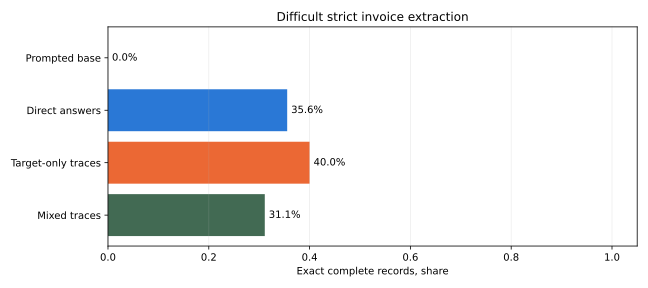

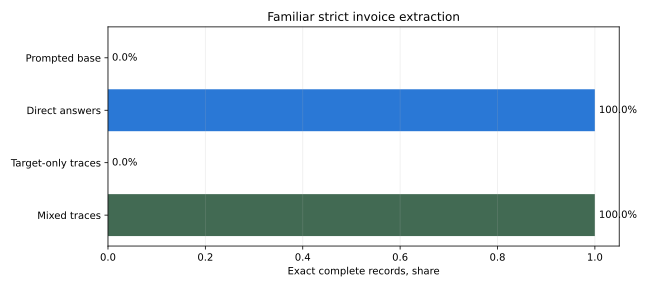

In [20]:
for name, values in slice_scores.items():
    plot_slices(values, f"{name} strict invoice extraction", filename=f"05-{name.lower()}-exact.svg")

## Read the result

    Return to SF-157375. Use the candidate ledger to explain why the label preserves the amount due.
    Then compare raw held-out answers to decide whether to keep the trace, how many familiar cases
    to reserve and whether the output cap is usable. Use the family intervals and single-fit scope
    when describing the outcome.

    [Return to the lesson](https://docs.recohut.com/courses/advanced-llm-fine-tuning/2-compare-training-stages/05-distil-verified-traces). [Together's Lao and Thai experiment](https://www.together.ai/blog/distilling-kimi-into-qwen).
    [Together's filtering recipe, Apache 2.0](https://github.com/togethercomputer/post-training-cookbook/blob/226e03ca225d6f13434047cf0f45ab3070a29801/post_training_cookbook/distillation/data.py).
    [Distilling Step-by-Step](https://aclanthology.org/2023.findings-acl.507/).